# فاز دوم پروژه آمار — بخش اول: احتمال‌های تجربی، شرطی، استقلال و بیز

**مسیر الف — NHANES August 2021–August 2023**  
**ادامه مستقیم فاز اول، با استفاده از فایل `final_data.csv` ساخته‌شده در نوت‌بوک `phase1.ipynb`.**

این نوت‌بوک **هیچ فایل خامی از CDC دانلود و دوباره ادغام نمی‌کند**. فقط دادهٔ نهایی فاز اول را می‌خواند و محاسبات احتمالاتی مرحلهٔ اول فاز دوم را انجام می‌دهد. تمام ستون‌های اصلی فاز اول حفظ می‌شوند؛ در این بخش فقط ستون‌های مرتبط با ویتامین D، جنسیت، سن و وزن استفاده می‌شوند.

**محدودهٔ تحلیل:** احتمال حاشیه‌ای، مشترک و شرطی، مقایسه خام/وزن‌دار، ارزیابی توصیفی استقلال و استفاده از قضیه بیز. **آزمون فرض، فاصله اطمینان، توزیع دوجمله‌ای/نرمال و کوواریانس هنوز در این نوت‌بوک انجام نمی‌شوند** و در بخش‌های بعدی فاز دوم یا فاز سوم قرار دارند.

**مستندات:**
- دستورالعمل پروژه، `amarpr.pdf`، صفحات ۸ تا ۱۰.
- [راهنمای NHANES 2021–2023](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?Cycle=2021-2023)
- [اطلاعات ویتامین D در NHANES](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/VID_L.htm)
- [تفسیر سطح ویتامین D؛ NIH](https://ods.od.nih.gov/factsheets/VitaminD-HealthProfessional/)

**بازآفرینی داده:** اگر فایل `final_data.csv` موجود نبود، ابتدا در انتهای فاز اول `final_data.to_csv("final_data.csv", index=False)` را اجرا و فایل را در پوشهٔ `data/` پروژه قرار دهید. این نوت‌بوک عمداً دادهٔ جایگزین دیگری استفاده نمی‌کند تا خطای ناخواسته در اتصال فازها رخ ندهد.

## ۱. پرسش‌های آماری و تعریف رویدادها

فرض کنید یک بزرگسال از جامعه‌ای که پیمایش برای آن طراحی شده انتخاب شود. متغیر تصادفی $D$ غلظت 25(OH)D کل سرم (nmol/L) و متغیر تصادفی $S$ جنس ثبت‌شده در NHANES است.

- **رویداد A:** $A=\{D<50\}$؛ سطح ویتامین D کمتر از ۵۰ nmol/L است.
- **رویداد B:** $B=\{S=2\}$؛ کد جنس ثبت‌شده «زن» است (`RIAGENDR=2`). کد `1` «مرد» است.

آستانه ۵۰، یک **مرز عملیاتی برای پایین‌تر از سطح کفایت اکثر افراد** است، نه تشخیص قطعی کمبود. NIH خطر کمبود را به‌ویژه برای کمتر از ۳۰ nmol/L ذکر می‌کند.

**قاعده مخرج:** در تحلیل مشترک A و B فقط رکوردهای ۱۸+ با `LBXVIDMS` معتبر، `RIAGENDR` معتبر و وزن خون‌گیری مثبت استفاده می‌شوند. افرادی با ویتامین D گمشده هرگز به دسته «A رخ نداده» منتقل نمی‌شوند.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

THRESHOLD_NMOL = 50.0

# Resolve data from current working directory or one level above.
# Works when the notebook is at project root or in project/notebooks/.
working_dir = Path.cwd()
candidates = [
    working_dir / 'data' / 'final_data.csv',
    working_dir / 'final_data.csv',
    working_dir.parent / 'data' / 'final_data.csv',
    working_dir.parent / 'final_data.csv',
]
found = next(((i, p) for i, p in enumerate(candidates) if p.is_file()), None)
saved = found[1] if found is not None else None
if saved is None:
    searched = '\n'.join(str(p) for p in candidates)
    raise FileNotFoundError(
        'The Phase 1 prepared dataset final_data.csv was not found.\n'
        'Export it from the final_data variable in phase1.ipynb, and place it '
        'at project root or inside data/.\nSearched paths:\n' + searched
    )

project_root = saved.parent.parent if found[0] in (0, 2) else saved.parent
out = project_root / 'reports' / 'phase2'
figure_dir = project_root / 'figures' / 'phase2'
out.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(saved, low_memory=False)
required = [
    'SEQN', 'RIDAGEYR', 'RIAGENDR', 'LBXVIDMS',
    'WTPH2YR', 'WTPH2YR_clean', 'SDMVSTRA', 'SDMVPSU',
]
not_found = sorted(set(required) - set(data.columns))
if not_found:
    raise KeyError('Missing Phase 1 columns: ' + ', '.join(not_found))
for col in required:
    data[col] = pd.to_numeric(data[col], errors='coerce')
if data['SEQN'].isna().any() or data['SEQN'].duplicated().any():
    raise ValueError('Invalid or duplicate participant ID: SEQN')

print('Source (Phase 1):', saved.resolve())
print('Number of participants:', len(data))
print('Number of columns retained:', data.shape[1])
print('Table output folder:', out.resolve())
assert data.shape[1] >= 20, 'Phase 1 final dataset has fewer columns than expected; verify export.'

Source (Phase 1): C:\Users\admin\Documents\vitamin-d-project\data\final_data.csv
Number of participants: 6337
Number of columns retained: 20
Table output folder: C:\Users\admin\Documents\vitamin-d-project\reports\phase2


## ۲. جامعه تحلیل، داده‌های گمشده و کنترل وزن‌ها

- **واحد مشاهده:** هر فرد (`SEQN`) یک بار.
- **جمعیت هدف عملیاتی:** بزرگسالان ۱۸ سال به بالای جمعیت تحت پوشش پیمایش NHANES در ۲۰۲۱–۲۰۲۳، با رعایت محدودیت‌های پاسخ به خون‌گیری.
- **وزن مورد استفاده:** `WTPH2YR_clean`؛ همان وزن خون‌گیری آماده‌شده در فاز اول.
- **کنترل سازگاری:** اختلاف وزن خام و تمیزشده فقط در مقادیر تقریباً صفرِ مستندسازی‌شدهٔ فاز اول مجاز است. بدون تغییر یا حذف خودکار سایر مقادیر.
- **مخرج احتمال‌های A و B:** فقط افراد دارای ویتامین D معتبر، جنس ثبت‌شده با کد ۱ یا ۲ و وزن مثبت.

**مهم:** صفر/گمشده بودن وزن در کل فایل را با کمبود ویتامین D اشتباه نمی‌گیریم. همچنین به دلیل کامل نبودن خون‌گیری، برآوردها برای افراد واجد شرایط و مطابق راهنمای وزن‌دهی تفسیر می‌شوند. طرح خوشه‌ای/طبقه‌ای برای خطای استاندارد در این مرحله محاسبه نمی‌شود.

In [2]:
# Verify the weight cleaning decision was inherited exactly from Phase 1.
raw_w = data['WTPH2YR']
clean_w = data['WTPH2YR_clean']
if raw_w.isna().any() or clean_w.isna().any():
    raise ValueError('Unexpected missing sampling weights; check Phase 1 export.')
if (clean_w < 0).any() or not np.isfinite(clean_w).all():
    raise ValueError('Invalid cleaned sampling weights.')
expected_clean = raw_w.mask(raw_w.gt(0) & raw_w.lt(1e-70), 0.)
if not np.allclose(clean_w, expected_clean, rtol=1e-12, atol=0.0):
    raise ValueError('WTPH2YR_clean is inconsistent with the weight handling documented in Phase 1.')

adults = data.loc[data['RIDAGEYR'].ge(18)].copy()
adults['weight'] = adults['WTPH2YR_clean']
has_vitd = adults['LBXVIDMS'].notna() & np.isfinite(adults['LBXVIDMS'])
valid_sex = adults['RIAGENDR'].isin([1, 2])
positive_weight = adults['weight'].gt(0)

analysis = adults.loc[has_vitd & valid_sex & positive_weight].copy()
analysis['A'] = analysis['LBXVIDMS'].lt(THRESHOLD_NMOL)
analysis['B'] = analysis['RIAGENDR'].eq(2)

checks = pd.DataFrame({
    'Indicator': [
        'All records in Phase 1 final dataset',
        'Adults 18+',
        'Adults with valid vitamin D',
        'Adults with valid recorded sex',
        'Adults with positive cleaned phlebotomy weight',
        'Adults eligible for this analysis',
        'Near-zero source weights reclassified as zero in Phase 1',
        'Unique participants in analysis',
    ],
    'Count': [
        len(data), len(adults), int(has_vitd.sum()), int(valid_sex.sum()),
        int(positive_weight.sum()), len(analysis),
        int((raw_w.gt(0) & raw_w.lt(1e-70)).sum()),
        int(analysis['SEQN'].nunique())
    ]
})
display(checks)
assert analysis['SEQN'].is_unique
assert analysis['LBXVIDMS'].gt(0).all()
assert analysis['weight'].gt(0).all()
assert np.isfinite(analysis['weight']).all()
if len(data) != 6337 or int(has_vitd.sum()) != 5824:
    print('NOTICE: The counts differ from the submitted Phase 1 data: review the input file.')

,Indicator,Count
0,All records in Phase 1 final dataset,6337
1,Adults 18+,6337
2,Adults with valid vitamin D,5824
3,Adults with valid recorded sex,6337
4,Adults with positive cleaned phlebotomy weight,6029
5,Adults eligible for this analysis,5824
6,Near-zero source weights reclassified as zero ...,308
7,Unique participants in analysis,5824


## ۳. محاسبه احتمال حاشیه‌ای، مشترک و شرطی

برای رویدادهای از پیش تعریف‌شدهٔ $A=\{D<50\}$ و $B=\{\text{sex = female}\}$، احتمال‌ها را با دو مخرج یکسانِ واجد شرایط می‌سنجیم: نسخهٔ خام (هر فرد با وزن یک) و نسخهٔ وزن‌دار (وزن خون‌گیری `WTPH2YR_clean`).

$$\widehat P_w(A)=\frac{\sum_i w_i\mathbf1(A_i)}{\sum_i w_i}, \qquad
\widehat P_w(A\cap B)=\frac{\sum_i w_i\mathbf1(A_i)\mathbf1(B_i)}{\sum_i w_i}.$$

$$\widehat P_w(A\mid B)=\frac{\widehat P_w(A\cap B)}{\widehat P_w(B)}.$$

**تفسیر:** وزن‌دهی برای توصیف نسبت‌های جمعیتی متناسب با طراحی نمونه‌گیری است؛ وزن‌ها به‌تنهایی محاسبهٔ خطای استاندارد صحیح بر اساس طرح خوشه‌ای و طبقه‌ای را تضمین نمی‌کنند.

In [3]:
def empirical_probabilities(frame, use_weights=False):
    a = frame['A'].to_numpy(dtype=bool)
    b = frame['B'].to_numpy(dtype=bool)
    w = frame['weight'].to_numpy(dtype=float) if use_weights else np.ones(len(frame))
    assert len(w) > 0 and np.isfinite(w).all() and (w >= 0).all() and w.sum() > 0
    rate = lambda mask: float(w[np.asarray(mask, dtype=bool)].sum()/w.sum())
    pa, pb = rate(a), rate(b)
    pab = rate(a & b)
    if pa <= 0 or pb <= 0 or pb >= 1:
        raise ValueError('Event probabilities are degenerate; conditional comparison is undefined.')
    result = {
        'P(A)': pa,
        'P(B)': pb,
        'P(A ∩ B)': pab,
        'P(A | B)': pab / pb,
        'P(A | not B)': (pa - pab) / (1 - pb),
        'P(B | A)': pab / pa,
        'P(A)P(B)': pa * pb,
        'Independence difference': pab - pa * pb,
    }
    return result

# تست عددی مستقل از داده واقعی؛ برای شناسایی خطای پیاده‌سازی
_test = pd.DataFrame({'A':[True,True,False,False],
                      'B':[True,False,True,False],
                      'weight':[1.,1.,1.,1.]})
test_result = empirical_probabilities(_test)
assert np.isclose(test_result['P(A ∩ B)'], 0.25)
assert np.isclose(test_result['P(A | B)'], 0.5)
assert np.isclose(test_result['Independence difference'], 0)

raw = empirical_probabilities(analysis)
weighted = empirical_probabilities(analysis, use_weights=True)
summary = pd.DataFrame({'Unweighted': raw, 'Survey-weighted': weighted})
summary['Weighted - unweighted (percentage points)'] = (
    summary['Survey-weighted'] - summary['Unweighted']
) * 100
print('Probabilities (0 to 1):')
display(summary.style.format('{:.5f}'))

Probabilities (0 to 1):


,Unweighted,Survey-weighted,Weighted - unweighted (percentage points)
P(A),0.20209,0.20838,0.62885
P(B),0.54619,0.51225,-3.39336
P(A ∩ B),0.09839,0.09798,-0.04096
P(A | B),0.18013,0.19126,1.11329
P(A | not B),0.22853,0.22636,-0.21664
P(B | A),0.48683,0.47017,-1.66571
P(A)P(B),0.11038,0.10675,-0.36365
Independence difference,-0.01200,-0.00877,0.32269


### جدول احتمال مشترک (۲×۲)

هر چهار خانه حاصل، مجموعاً یک می‌شوند. مقدار خانه `(A=True, B=True)` همان احتمال مشترک $P(A\cap B)$ است. سطرها نشان می‌دهند فرد پایین‌تر از آستانه ۵۰ قرار دارد یا خیر و ستون‌ها جنس ثبت‌شده را نمایش می‌دهند.

In [4]:
def joint_table(frame, use_weights=False):
    tmp = frame.copy()
    tmp['mass'] = tmp['weight'] if use_weights else 1.0
    tab = tmp.pivot_table(index='A', columns='B', values='mass',
                          aggfunc='sum', fill_value=0)
    tab = tab.reindex(index=[False, True], columns=[False, True], fill_value=0)
    return tab / tab.to_numpy().sum()

raw_joint = joint_table(analysis)
w_joint = joint_table(analysis, use_weights=True)
assert np.isclose(raw_joint.to_numpy().sum(), 1)
assert np.isclose(w_joint.to_numpy().sum(), 1)
assert np.isclose(w_joint.loc[True,True],weighted['P(A ∩ B)'])

print('Joint probability table — raw:')
display(raw_joint.rename(index={False:'A=no',True:'A=yes'}, columns={False:'Male',True:'Female'}).round(5))
print('Joint probability table — survey-weighted:')
display(w_joint.rename(index={False:'A=no',True:'A=yes'}, columns={False:'Male',True:'Female'}).round(5))

Joint probability table — raw:


B,Male,Female
A,,
A=no,0.35010,0.44780
A=yes,0.10371,0.09839


Joint probability table — survey-weighted:


B,Male,Female
A,,
A=no,0.37734,0.41428
A=yes,0.11041,0.09798


## ۴. بررسی استقلال (صرفاً توصیفی)

اگر A و B مستقل باشند، خواهیم داشت: $P(A\cap B)=P(A)P(B)$ و نیز $P(A\mid B)=P(A)$.

اختلاف محاسبه‌شده میان این عبارت‌ها نشان‌دهنده **میزان تفاوت توصیفی** است؛ هیچ آزمون معناداری در این بخش انجام نمی‌دهیم. از این رو نمی‌توان صرفاً از غیرصفر بودن یک اختلاف نمونه‌ای نتیجه گرفت که در کل جامعه استقلال وجود ندارد.

## ۵. قضیه بیز

$$P(B\mid A)=\frac{P(A\mid B)P(B)}{P(A)}.$$

در اینجا $P(B\mid A)$ احتمال زن بودن در بین بزرگسالان دارای ویتامین D پایین‌تر از ۵۰ است؛ **متفاوت** با $P(A\mid B)$ که احتمال پایین‌تر از آستانه بودن در بین زنان است. بیز رابطه دقیق این دو احتمال معکوس را نشان می‌دهد.

Unweighted: P(A|B)=0.1801, P(A|not B)=0.2285, P(B|A) by Bayes=0.4868, P(A∩B)-P(A)P(B)=-0.01200
Survey-weighted: P(A|B)=0.1913, P(A|not B)=0.2264, P(B|A) by Bayes=0.4702, P(A∩B)-P(A)P(B)=-0.00877


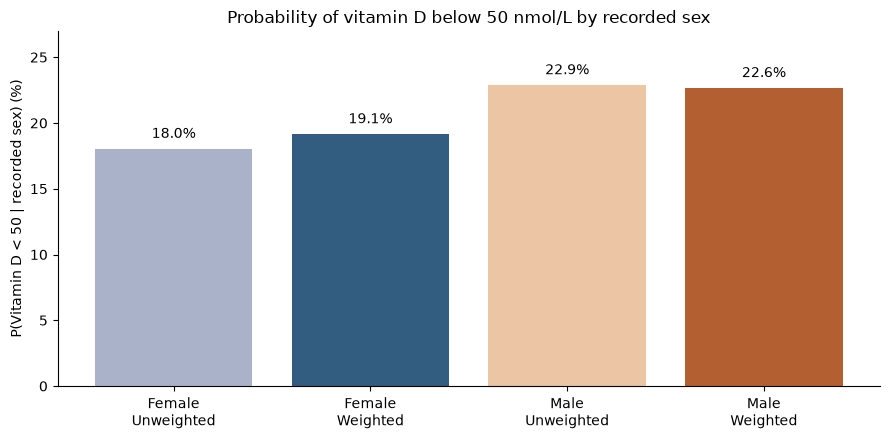

Figure saved: C:\Users\admin\Documents\vitamin-d-project\figures\phase2\phase2_step1_conditional_probabilities.png


In [5]:
for label, result in [('Unweighted', raw), ('Survey-weighted', weighted)]:
    bayes = result['P(A | B)'] * result['P(B)'] / result['P(A)']
    assert np.isclose(bayes, result['P(B | A)'])
    print(f'{label}: P(A|B)={result["P(A | B)"]:.4f}, '
          f'P(A|not B)={result["P(A | not B)"]:.4f}, '
          f'P(B|A) by Bayes={bayes:.4f}, '
          f'P(A∩B)-P(A)P(B)={result["Independence difference"]:+.5f}')

plot_vals = [raw['P(A | B)'], weighted['P(A | B)'],
             raw['P(A | not B)'], weighted['P(A | not B)']]
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = ['Female\nUnweighted', 'Female\nWeighted',
          'Male\nUnweighted', 'Male\nWeighted']
bars = ax.bar(labels, np.array(plot_vals)*100,
              color=['#A9B2C8','#335C81','#EBC5A4','#B45F32'])
ax.set_ylabel('P(Vitamin D < 50 | recorded sex) (%)')
ax.set_title('Probability of vitamin D below 50 nmol/L by recorded sex')
ax.set_ylim(0, min(100, max(plot_vals)*118))
for bar, value in zip(bars, plot_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.6,
            f'{value*100:.1f}%', ha='center', va='bottom', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()
plot_path = figure_dir / 'phase2_step1_conditional_probabilities.png'
fig.savefig(plot_path, dpi=180, bbox_inches='tight')
plt.show()
print('Figure saved:', plot_path)

## ۶. تفسیر آماری و خروجی مرحلهٔ اول

۱. `P(A)` برآورد احتمال قرار گرفتن ویتامین D پایین‌تر از ۵۰ در میان بزرگسالان واجد شرایط است.

۲. `P(A | B)` و `P(A | not B)` به‌ترتیب این احتمال را در گروه‌های جنس ثبت‌شدهٔ زن و مرد نشان می‌دهند. مقایسهٔ آن‌ها **توصیفی** است.

۳. اختلاف میان احتمال خام و وزن‌دار، اثر ترکیب نمونه و وزن‌های نامساوی را نشان می‌دهد؛ این اختلاف به معنی خطای یکی از دو محاسبه نیست.

۴. برای استقلال، اختلاف `P(A∩B) - P(A)P(B)` را محاسبه می‌کنیم؛ غیرصفر شدن اختلاف نمونه‌ای به تنهایی آزمون معنی‌داری نیست.

۵. قضیهٔ بیز `P(B|A)` را از `P(A|B)` و دو احتمال حاشیه‌ای به دست می‌دهد و مقدار آن در کد با محاسبهٔ مستقیم مقایسه می‌شود.

**محدودیت‌ها:** مطالعه مشاهده‌ای و مقطعی است؛ کمبود داده‌های آزمایشگاهی وجود دارد؛ تعریف «زیر ۵۰» آستانهٔ عملیاتی و نه تشخیص قطعی بالینی است؛ برآوردهای این نوت‌بوک فاقد فاصله اطمینان/خطای استانداردِ تعدیل‌شده برای طرح پیچیده هستند و هیچ ادعای علّی نمی‌کنند.

خروجی‌ها در پوشهٔ `phase2_outputs` کنار فایل `final_data.csv` قرار می‌گیرند؛ فایل فردی دوباره منتشر نمی‌شود.

**ساختار خروجی مخزن:** جدول‌ها در `reports/phase2/` و نمودار در `figures/phase2/` ذخیره می‌شوند. فایل دادهٔ فردمحور `data/final_data.csv` فقط محلی است و نباید در GitHub یا بستهٔ تحویل قرار گیرد.

In [6]:
# Save concise results; do not export individual-level observations.
summary.to_csv(out / 'phase2_step1_probability_summary.csv', encoding='utf-8-sig')
w_joint.to_csv(out / 'phase2_step1_weighted_joint_table.csv', encoding='utf-8-sig')
checks.to_csv(out / 'phase2_step1_data_audit.csv', index=False, encoding='utf-8-sig')

print('Files saved:')
for path in sorted(out.glob('phase2_step1_*')):
    print(' -', path)
print('Figure saved at:', figure_dir / 'phase2_step1_conditional_probabilities.png')
print('✔ Stage 1 complete. Next: binomial model, normal approximation, moments, covariance.')

Files saved:
 - C:\Users\admin\Documents\vitamin-d-project\reports\phase2\phase2_step1_data_audit.csv
 - C:\Users\admin\Documents\vitamin-d-project\reports\phase2\phase2_step1_probability_summary.csv
 - C:\Users\admin\Documents\vitamin-d-project\reports\phase2\phase2_step1_weighted_joint_table.csv
Figure saved at: C:\Users\admin\Documents\vitamin-d-project\figures\phase2\phase2_step1_conditional_probabilities.png
✔ Stage 1 complete. Next: binomial model, normal approximation, moments, covariance.
